In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy

  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.5 MB ? eta -:--:--
   ---- -----------------------------------

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset

In [19]:
X = pd.read_csv(
    "../data/secom.data",
    sep=r"\s+",
    header=None
)


# Load feature dataset

In [20]:
X = pd.read_csv(
    "../data/secom.data",
    sep=r"\s+",
    header=None
)

# Load target labels

In [21]:
labels = pd.read_csv(
    "../data/secom_labels.data",
    sep=r"\s+",
    header=None
)

y = labels.iloc[:, 0]

print("Dataset loaded successfully!")

Dataset loaded successfully!


# Dataset information


In [22]:
print("Dataset shape:", X.shape)

print("\nTarget shape:", y.shape)

print("\nData types:")
print(X.dtypes.value_counts())

print("\nClass distribution:")
print(y.value_counts())

print("\nTotal missing values:")
print(X.isnull().sum().sum())

print("\nMissing value percentage:")
print(
    X.isnull().sum().sum()
    / X.size * 100
)

Dataset shape: (1567, 590)

Target shape: (1567,)

Data types:
float64    590
Name: count, dtype: int64

Class distribution:
0
-1    1463
 1     104
Name: count, dtype: int64

Total missing values:
41951

Missing value percentage:
4.537548808583821


# Calculate missing values for each feature

In [23]:
missing_count = X.isnull().sum()

# Calculate missing percentage for each feature

In [24]:
missing_percentage = (missing_count / len(X)) * 100

# Create a summary DataFrame

In [25]:
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Sort features by missing percentage

In [26]:
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

# Display the top 20 features

In [27]:
print("Top 20 features with missing values:")
display(missing_summary.head(20))

Top 20 features with missing values:


,Missing_Count,Missing_Percentage
292,1429,91.193363
293,1429,91.193363
158,1429,91.193363
157,1429,91.193363
492,1341,85.577537
85,1341,85.577537
358,1341,85.577537
220,1341,85.577537
244,1018,64.964901
517,1018,64.964901


# Visualize missing values

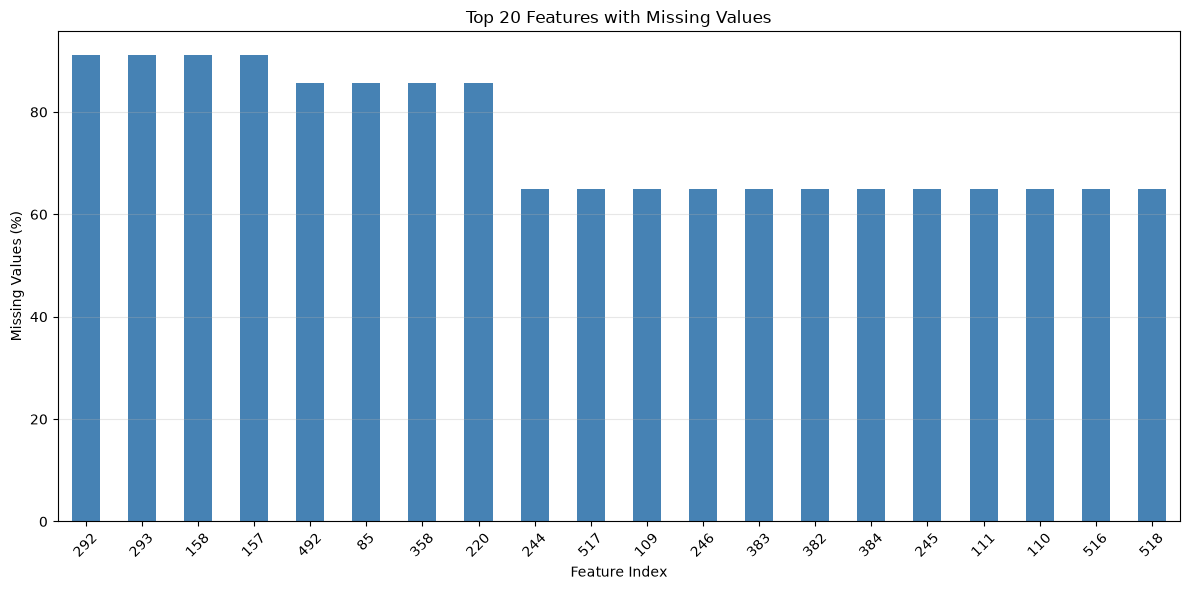

In [28]:

plt.figure(figsize=(12, 6))

missing_summary.head(20)["Missing_Percentage"].plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Feature Index")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Calculate overall missing-value statistics

In [29]:
total_missing = X.isnull().sum().sum()
total_values = X.size

overall_missing_percentage = (
    total_missing / total_values
) * 100

features_with_missing = (missing_count > 0).sum()

features_without_missing = (missing_count == 0).sum()

print("Missing Value Analysis")
print("-" * 40)

print("Total features:", X.shape[1])
print("Total samples:", X.shape[0])

print("Total missing values:", total_missing)

print(
    "Overall missing percentage:",
    round(overall_missing_percentage, 2), "%"
)

print(
    "Features containing missing values:",
    features_with_missing
)

print(
    "Features without missing values:",
    features_without_missing
)


Missing Value Analysis
----------------------------------------
Total features: 590
Total samples: 1567
Total missing values: 41951
Overall missing percentage: 4.54 %
Features containing missing values: 538
Features without missing values: 52


# Analyze missing-value thresholds

In [30]:
thresholds = [0, 5, 10, 20, 30, 40, 50, 60, 80]

for threshold in thresholds:

    count = (
        missing_percentage > threshold
    ).sum()

    print(
        f"Features with more than {threshold}% missing values: {count}"
    )


Features with more than 0% missing values: 538
Features with more than 5% missing values: 52
Features with more than 10% missing values: 52
Features with more than 20% missing values: 32
Features with more than 30% missing values: 32
Features with more than 40% missing values: 32
Features with more than 50% missing values: 28
Features with more than 60% missing values: 24
Features with more than 80% missing values: 8


# Visualize the overall missing-value pattern

In [ ]:
import seaborn as sns

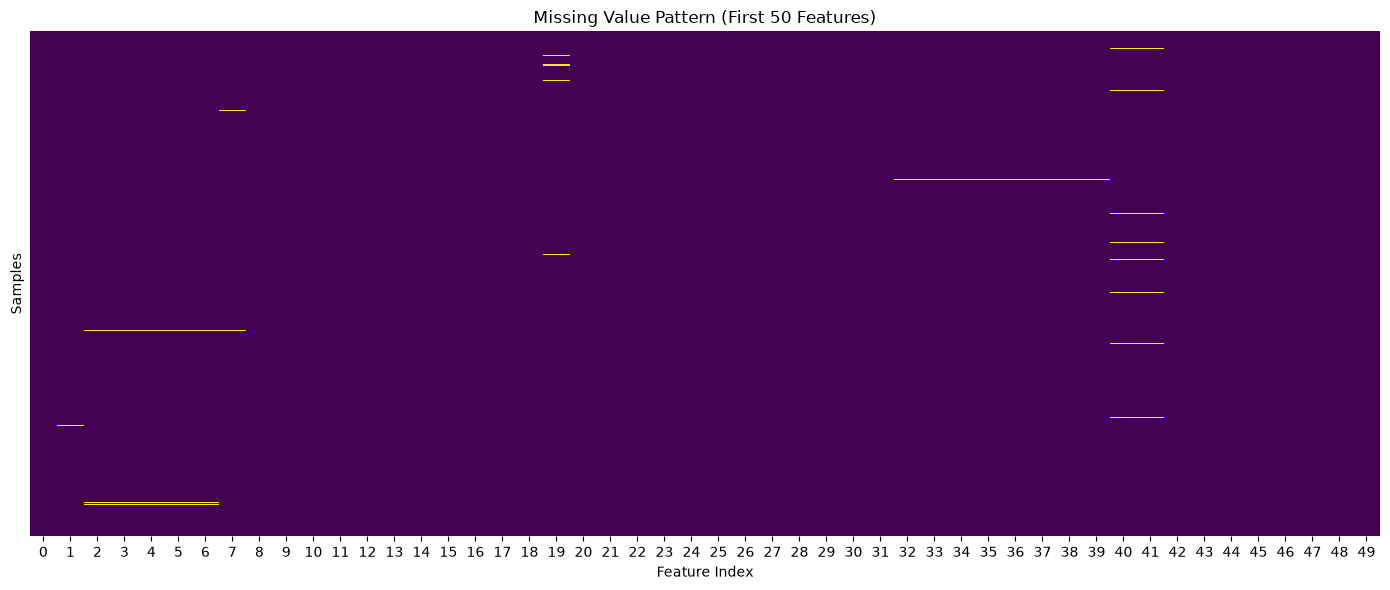

In [34]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    X.iloc[:, :50].isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Value Pattern (First 50 Features)")
plt.xlabel("Feature Index")
plt.ylabel("Samples")

plt.tight_layout()
plt.show()


# Identify features with more than 50% missing values

In [35]:
high_missing_features = missing_summary[
    missing_summary["Missing_Percentage"] > 50
]

print("Features with more than 50% missing values:")
print(high_missing_features)

print("\nTotal:", len(high_missing_features))

Features with more than 50% missing values:
     Missing_Count  Missing_Percentage
292           1429           91.193363
293           1429           91.193363
158           1429           91.193363
157           1429           91.193363
492           1341           85.577537
85            1341           85.577537
358           1341           85.577537
220           1341           85.577537
244           1018           64.964901
517           1018           64.964901
109           1018           64.964901
246           1018           64.964901
383           1018           64.964901
382           1018           64.964901
384           1018           64.964901
245           1018           64.964901
111           1018           64.964901
110           1018           64.964901
516           1018           64.964901
518           1018           64.964901
580            949           60.561583
578            949           60.561583
579            949           60.561583
581            949  

# Visualize missing-value distribution

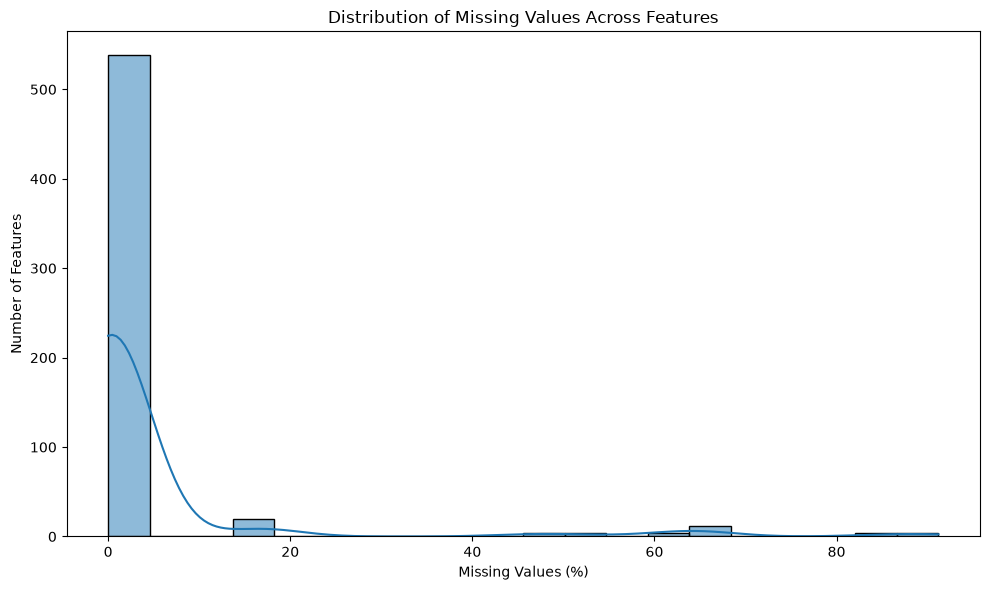

In [36]:
plt.figure(figsize=(10, 6))

sns.histplot(
    missing_percentage,
    bins=20,
    kde=True
)

plt.title("Distribution of Missing Values Across Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Number of Features")

plt.tight_layout()
plt.show()


# Calculate missing values for each sample

In [37]:
missing_per_sample = X.isnull().sum(axis=1)

print("Missing values per sample:")
print(missing_per_sample.describe())

Missing values per sample:
count    1567.000000
mean       26.771538
std        13.377518
min         4.000000
25%        20.000000
50%        24.000000
75%        32.000000
max       152.000000
dtype: float64


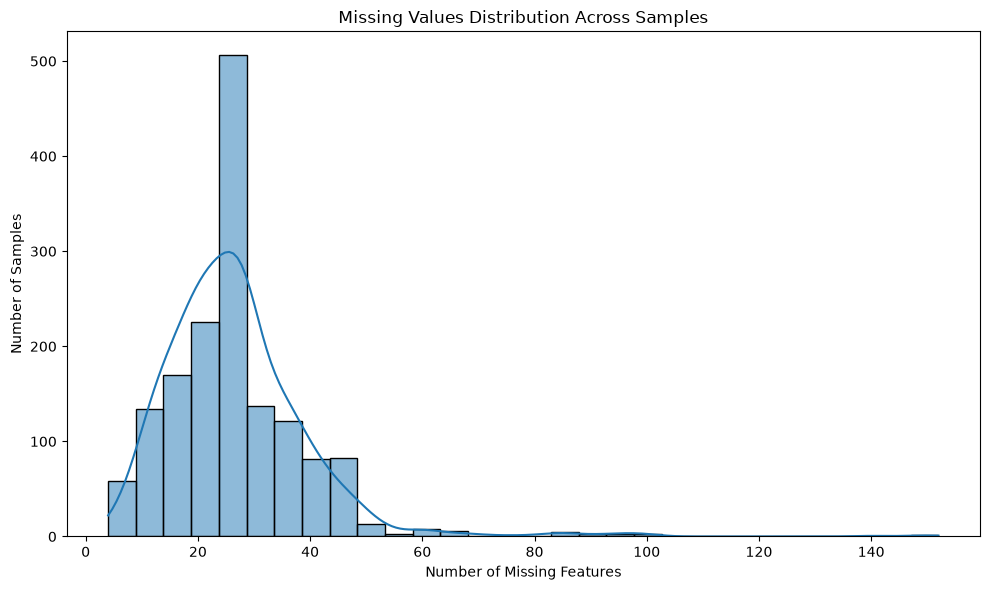

In [38]:
plt.figure(figsize=(10, 6))

sns.histplot(
    missing_per_sample,
    bins=30,
    kde=True
)

plt.title("Missing Values Distribution Across Samples")
plt.xlabel("Number of Missing Features")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()


# Create a DataFrame containing missing-value information

In [39]:
sample_analysis = pd.DataFrame({
    "Missing_Count": X.isnull().sum(axis=1),
    "Missing_Percentage": (X.isnull().sum(axis=1) / X.shape[1]) * 100,
    "Target": y
})

print(sample_analysis.head())

   Missing_Count  Missing_Percentage  Target
0             44            7.457627      -1
1             36            6.101695      -1
2             20            3.389831       1
3             20            3.389831      -1
4             40            6.779661      -1


# Compare missing values by target class

In [40]:
class_missing_analysis = sample_analysis.groupby(
    "Target"
).agg({
    "Missing_Count": ["mean", "median", "min", "max"],
    "Missing_Percentage": ["mean", "median"]
})

print(class_missing_analysis)

       Missing_Count                 Missing_Percentage          
                mean median min  max               mean    median
Target                                                           
-1         26.864662   24.0   4  152           4.553332  4.067797
 1         25.461538   24.0   8   64           4.315515  4.067797


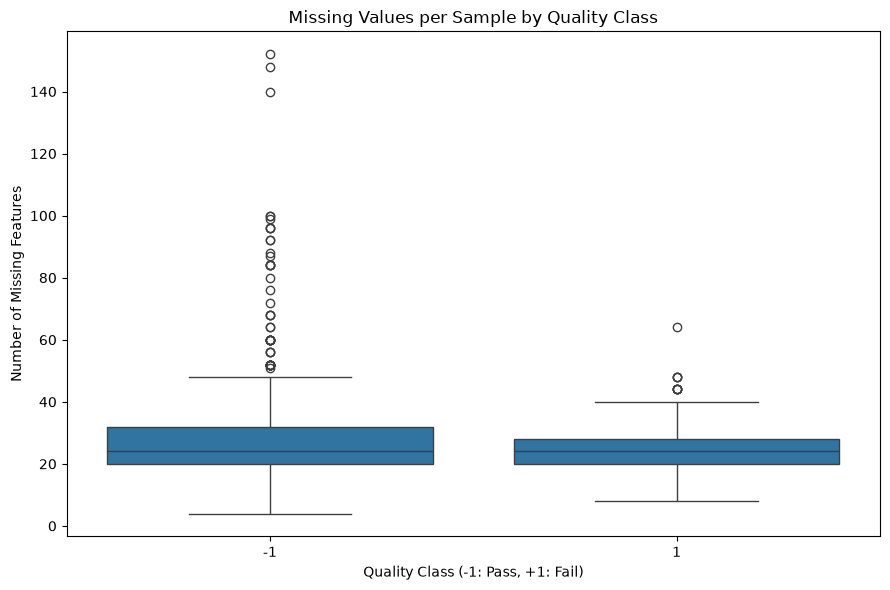

In [41]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=sample_analysis,
    x="Target",
    y="Missing_Count"
)

plt.title("Missing Values per Sample by Quality Class")
plt.xlabel("Quality Class (-1: Pass, +1: Fail)")
plt.ylabel("Number of Missing Features")

plt.tight_layout()
plt.show()


In [42]:
from scipy.stats import mannwhitneyu

pass_missing = sample_analysis.loc[
    sample_analysis["Target"] == -1,
    "Missing_Count"
]

fail_missing = sample_analysis.loc[
    sample_analysis["Target"] == 1,
    "Missing_Count"
]

statistic, p_value = mannwhitneyu(
    pass_missing,
    fail_missing,
    alternative="two-sided"
)

print("Mann-Whitney U Test")
print("-------------------")
print("U statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is evidence of a difference between the two groups.")
else:
    print("No statistically significant difference was detected.")


Mann-Whitney U Test
-------------------
U statistic: 80233.5
P-value: 0.3477060013432921
No statistically significant difference was detected.


# Missing Value Imputation Comparison

In [43]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training shape: (1253, 590)
Testing shape: (314, 590)

Training target distribution:
0
-1    1170
 1      83
Name: count, dtype: int64

Testing target distribution:
0
-1    293
 1     21
Name: count, dtype: int64


In [44]:
# Define imputation strategies
strategies = ["mean", "median", "most_frequent"]

for strategy in strategies:

    imputer = SimpleImputer(
        strategy=strategy,
        keep_empty_features=True
    )

    # Learn imputation values from training data
    X_train_imputed = imputer.fit_transform(X_train)

    # Apply learned values to testing data
    X_test_imputed = imputer.transform(X_test)

    print(f"\nStrategy: {strategy}")
    print("Training shape:", X_train_imputed.shape)
    print("Testing shape:", X_test_imputed.shape)

    print(
        "Remaining missing values:",
        np.isnan(X_train_imputed).sum()
    )



Strategy: mean
Training shape: (1253, 590)
Testing shape: (314, 590)
Remaining missing values: 0

Strategy: median
Training shape: (1253, 590)
Testing shape: (314, 590)
Remaining missing values: 0

Strategy: most_frequent
Training shape: (1253, 590)
Testing shape: (314, 590)
Remaining missing values: 0


# Feature Filtering Based on Missing Value Percentage

In [45]:
# Calculate missing percentage using training data

train_missing_percentage = (
    X_train.isnull().mean() * 100
)

# Compare different thresholds
thresholds = [20, 30, 40, 50, 60, 80]

print("Feature Filtering Analysis")
print("-" * 45)

for threshold in thresholds:

    features_to_remove = (
        train_missing_percentage > threshold
    ).sum()

    features_to_keep = (
        train_missing_percentage <= threshold
    ).sum()

    print(f"\nThreshold: {threshold}%")
    print("Features to remove:", features_to_remove)
    print("Features to keep:", features_to_keep)


Feature Filtering Analysis
---------------------------------------------

Threshold: 20%
Features to remove: 32
Features to keep: 558

Threshold: 30%
Features to remove: 32
Features to keep: 558

Threshold: 40%
Features to remove: 32
Features to keep: 558

Threshold: 50%
Features to remove: 24
Features to keep: 566

Threshold: 60%
Features to remove: 24
Features to keep: 566

Threshold: 80%
Features to remove: 8
Features to keep: 582


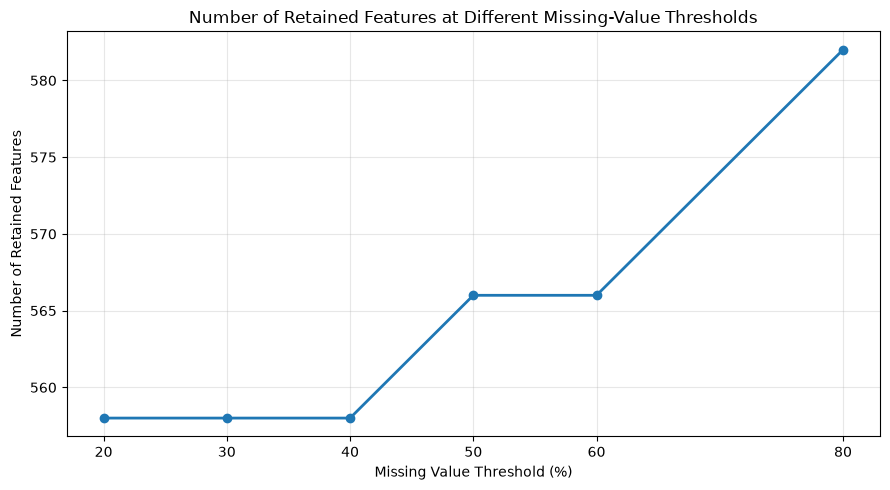

In [46]:
thresholds = [20, 30, 40, 50, 60, 80]

features_kept = []

for threshold in thresholds:

    count = (
        train_missing_percentage <= threshold
    ).sum()

    features_kept.append(count)


plt.figure(figsize=(9, 5))

plt.plot(
    thresholds,
    features_kept,
    marker="o",
    linewidth=2
)

plt.title("Number of Retained Features at Different Missing-Value Thresholds")
plt.xlabel("Missing Value Threshold (%)")
plt.ylabel("Number of Retained Features")

plt.xticks(thresholds)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Identifying Features with Excessive Missing Values

In [47]:
# Set our candidate missing-value threshold
MISSING_THRESHOLD = 50

# Calculate missing percentages in training data
train_missing_percentage = X_train.isnull().mean() * 100

# Identify features to remove
features_to_remove = train_missing_percentage[
    train_missing_percentage > MISSING_THRESHOLD
].index.tolist()

# Identify features to retain
features_to_keep = train_missing_percentage[
    train_missing_percentage <= MISSING_THRESHOLD
].index.tolist()

print("Missing value threshold:", MISSING_THRESHOLD, "%")

print("\nFeatures to remove:")
print(features_to_remove)

print("\nTotal features to remove:", len(features_to_remove))

print("\nTotal features to retain:", len(features_to_keep))


Missing value threshold: 50 %

Features to remove:
[85, 109, 110, 111, 157, 158, 220, 244, 245, 246, 292, 293, 358, 382, 383, 384, 492, 516, 517, 518, 578, 579, 580, 581]

Total features to remove: 24

Total features to retain: 566


In [48]:
# Remove high-missing-value features
X_train_filtered = X_train[features_to_keep].copy()

X_test_filtered = X_test[features_to_keep].copy()

print("Original training shape:", X_train.shape)
print("Filtered training shape:", X_train_filtered.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Filtered testing shape:", X_test_filtered.shape)


Original training shape: (1253, 590)
Filtered training shape: (1253, 566)

Original testing shape: (314, 590)
Filtered testing shape: (314, 566)


# Median Imputation

In [49]:
from sklearn.impute import SimpleImputer

# Create median imputer
median_imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

# Fit on training data and transform
X_train_imputed = median_imputer.fit_transform(
    X_train_filtered
)

# Apply learned medians to testing data
X_test_imputed = median_imputer.transform(
    X_test_filtered
)

print("Median imputation completed!")

print("\nTraining shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

print(
    "\nMissing values in training:",
    np.isnan(X_train_imputed).sum()
)

print(
    "Missing values in testing:",
    np.isnan(X_test_imputed).sum()
)


Median imputation completed!

Training shape: (1253, 566)
Testing shape: (314, 566)

Missing values in training: 0
Missing values in testing: 0


In [50]:
# Convert imputed arrays back to DataFrames
# Preserve the original feature names (column indices)

X_train_imputed_df = pd.DataFrame(
    X_train_imputed,
    columns=features_to_keep,
    index=X_train_filtered.index
)

X_test_imputed_df = pd.DataFrame(
    X_test_imputed,
    columns=features_to_keep,
    index=X_test_filtered.index
)

# Check missing values
print("Training missing values:")
print(X_train_imputed_df.isnull().sum().sum())

print("\nTesting missing values:")
print(X_test_imputed_df.isnull().sum().sum())

# Check remaining shapes
print("\nTraining dataset:", X_train_imputed_df.shape)
print("Testing dataset:", X_test_imputed_df.shape)


Training missing values:
0

Testing missing values:
0

Training dataset: (1253, 566)
Testing dataset: (314, 566)


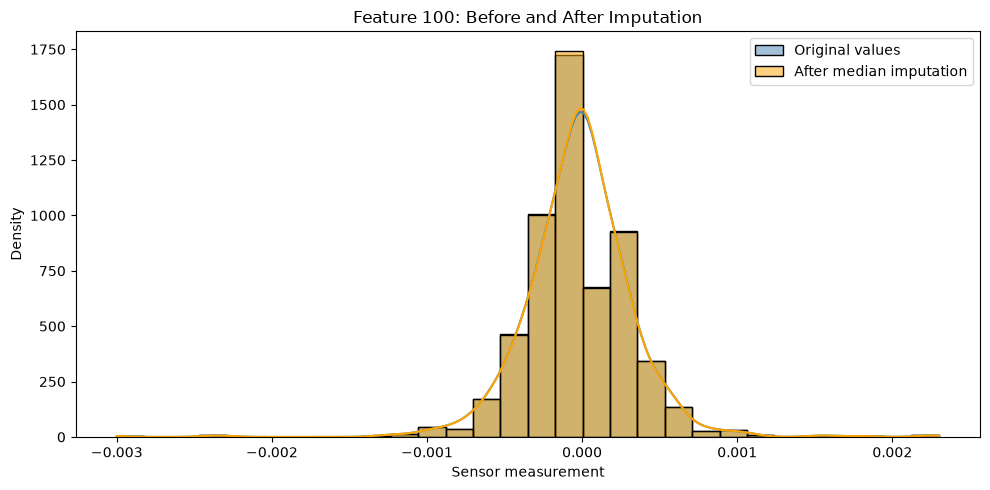

In [51]:
feature_index = 100

if feature_index in features_to_keep:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        X_train_filtered[feature_index].dropna(),
        bins=30,
        kde=True,
        label="Original values",
        color="steelblue",
        stat="density"
    )

    sns.histplot(
        X_train_imputed_df[feature_index],
        bins=30,
        kde=True,
        label="After median imputation",
        color="orange",
        stat="density"
    )

    plt.title(
        f"Feature {feature_index}: Before and After Imputation"
    )

    plt.xlabel("Sensor measurement")
    plt.ylabel("Density")
    plt.legend()

    plt.tight_layout()
    plt.show()

else:
    print("Feature 100 was removed. Choose another retained feature.")


# Variance Analysis and Constant Feature Removal

In [52]:
# Calculate variance using the imputed training dataset

feature_variance = X_train_imputed_df.var()

# Create a summary
variance_summary = pd.DataFrame({
    "Variance": feature_variance,
    "Standard_Deviation": X_train_imputed_df.std()
})

# Sort features by variance
variance_summary = variance_summary.sort_values(
    by="Variance",
    ascending=True
)

print("Features with the lowest variance:")
display(variance_summary.head(20))


Features with the lowest variance:


,Variance,Standard_Deviation
509,0.0,0.0
512,0.0,0.0
508,0.0,0.0
513,0.0,0.0
5,0.0,0.0
515,0.0,0.0
514,0.0,0.0
506,0.0,0.0
505,0.0,0.0
504,0.0,0.0


In [53]:
# Identify features with exactly zero variance

zero_variance_features = feature_variance[
    feature_variance == 0
].index.tolist()

print("Zero-variance features:")
print(zero_variance_features)

print("\nTotal zero-variance features:")
print(len(zero_variance_features))

print("\nFeatures before variance filtering:")
print(X_train_imputed_df.shape[1])


Zero-variance features:
[5, 13, 42, 49, 52, 69, 97, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538]

Total zero-variance features:
116

Features before variance filtering:
566


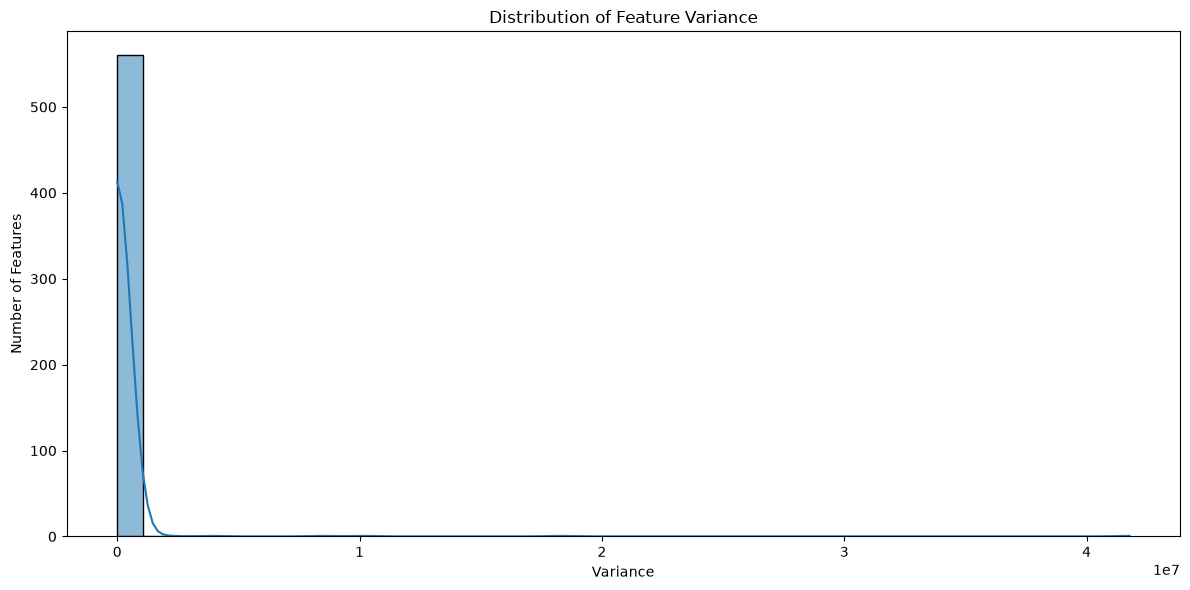

In [54]:
plt.figure(figsize=(12, 6))

sns.histplot(
    feature_variance,
    bins=40,
    kde=True
)

plt.title("Distribution of Feature Variance")
plt.xlabel("Variance")
plt.ylabel("Number of Features")

plt.tight_layout()
plt.show()


In [55]:
from sklearn.feature_selection import VarianceThreshold

# Create variance selector
variance_selector = VarianceThreshold(threshold=0)

# Fit on training data
X_train_variance_filtered = variance_selector.fit_transform(
    X_train_imputed_df
)

# Apply to testing data
X_test_variance_filtered = variance_selector.transform(
    X_test_imputed_df
)

print("Before variance filtering:")
print("Training:", X_train_imputed_df.shape)
print("Testing:", X_test_imputed_df.shape)

print("\nAfter variance filtering:")
print("Training:", X_train_variance_filtered.shape)
print("Testing:", X_test_variance_filtered.shape)


Before variance filtering:
Training: (1253, 566)
Testing: (314, 566)

After variance filtering:
Training: (1253, 450)
Testing: (314, 450)


In [56]:
# Get the features retained by VarianceThreshold

variance_feature_mask = variance_selector.get_support()

variance_features = X_train_imputed_df.columns[
    variance_feature_mask
].tolist()

print("Features before variance filtering:",
      X_train_imputed_df.shape[1])

print("Features after variance filtering:",
      len(variance_features))

print("\nRetained feature indices:")
print(variance_features)


Features before variance filtering: 566
Features after variance filtering: 450

Retained feature indices:
[0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 47, 48, 50, 51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 142, 143, 144, 145, 146, 147, 148, 150, 151, 152, 153, 154, 155, 156, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 180, 181, 182, 183, 184, 185, 187, 188, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 221, 222, 223,

In [57]:
# Preserve original feature indices

X_train_variance_df = pd.DataFrame(
    X_train_variance_filtered,
    columns=variance_features,
    index=X_train_imputed_df.index
)

X_test_variance_df = pd.DataFrame(
    X_test_variance_filtered,
    columns=variance_features,
    index=X_test_imputed_df.index
)

print("Training dataset:", X_train_variance_df.shape)
print("Testing dataset:", X_test_variance_df.shape)

print("\nRemaining missing values:")
print(X_train_variance_df.isnull().sum().sum())
print(X_test_variance_df.isnull().sum().sum())


Training dataset: (1253, 450)
Testing dataset: (314, 450)

Remaining missing values:
0
0


# Feature Selection Using ANOVA F-test

In [58]:
from sklearn.feature_selection import SelectKBest, f_classif

# Select the best 20 features using ANOVA
anova_selector = SelectKBest(
    score_func=f_classif,
    k=20
)

# Fit on training data
X_train_anova = anova_selector.fit_transform(
    X_train_variance_df,
    y_train
)

# Apply the same selection to testing data
X_test_anova = anova_selector.transform(
    X_test_variance_df
)

# Get selected original feature indices
anova_features = X_train_variance_df.columns[
    anova_selector.get_support()
].tolist()

print("ANOVA feature selection completed!")

print("\nTraining shape:", X_train_anova.shape)
print("Testing shape:", X_test_anova.shape)

print("\nSelected feature indices:")
print(anova_features)


ANOVA feature selection completed!

Training shape: (1253, 20)
Testing shape: (314, 20)

Selected feature indices:
[21, 28, 59, 64, 95, 100, 103, 122, 124, 125, 129, 316, 348, 351, 430, 431, 434, 435, 436, 510]


In [59]:
from sklearn.feature_selection import mutual_info_classif

# Calculate mutual information scores
mi_scores = mutual_info_classif(
    X_train_variance_df,
    y_train,
    random_state=42
)

# Create feature score DataFrame
mi_summary = pd.DataFrame({
    "Feature": X_train_variance_df.columns,
    "MI_Score": mi_scores
})

# Sort from highest to lowest
mi_summary = mi_summary.sort_values(
    by="MI_Score",
    ascending=False
)

print("Top 20 features using Mutual Information:")
display(mi_summary.head(20))


Top 20 features using Mutual Information:


,Feature,MI_Score
317,411,0.031132
117,128,0.030448
223,277,0.027955
405,541,0.025317
347,443,0.025271
448,588,0.023839
441,577,0.023720
312,406,0.023561
221,274,0.023304
319,413,0.023101


In [60]:
# Select top 20 features based on MI scores

mi_features = mi_summary.head(20)["Feature"].tolist()

# Extract selected features
X_train_mi = X_train_variance_df[mi_features]

X_test_mi = X_test_variance_df[mi_features]

print("Mutual Information selection completed!")

print("\nTraining shape:", X_train_mi.shape)
print("Testing shape:", X_test_mi.shape)

print("\nSelected feature indices:")
print(mi_features)


Mutual Information selection completed!

Training shape: (1253, 20)
Testing shape: (314, 20)

Selected feature indices:
[411, 128, 277, 541, 443, 588, 577, 406, 274, 413, 519, 412, 91, 131, 570, 589, 269, 70, 275, 331]


In [61]:
# Compare selected features

common_features = set(anova_features).intersection(
    set(mi_features)
)

print("ANOVA selected features:", len(anova_features))

print("Mutual Information selected features:", len(mi_features))

print("Common selected features:", len(common_features))

print("\nCommon feature indices:")
print(sorted(common_features))


ANOVA selected features: 20
Mutual Information selected features: 20
Common selected features: 0

Common feature indices:
[]


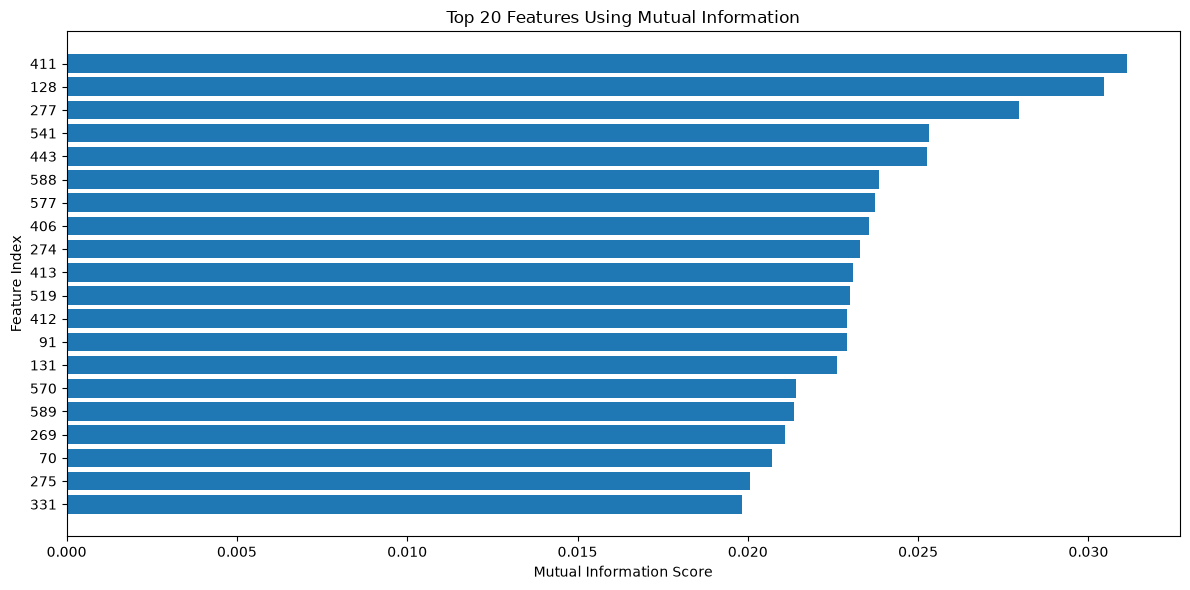

In [62]:
plt.figure(figsize=(12, 6))

top_mi = mi_summary.head(20).sort_values(
    by="MI_Score",
    ascending=True
)

plt.barh(
    top_mi["Feature"].astype(str),
    top_mi["MI_Score"]
)

plt.title("Top 20 Features Using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature Index")

plt.tight_layout()
plt.show()


In [63]:
# Extract ANOVA scores and p-values

anova_summary = pd.DataFrame({
    "Feature": X_train_variance_df.columns,
    "F_Score": anova_selector.scores_,
    "P_Value": anova_selector.pvalues_
})

# Sort by F-score
anova_summary = anova_summary.sort_values(
    by="F_Score",
    ascending=False
)

print("Top 20 ANOVA features:")
display(anova_summary.head(20))


Top 20 ANOVA features:


,Feature,F_Score,P_Value
95,103,38.345328,8.023813e-10
392,510,26.408693,3.202814e-07
54,59,20.145968,7.835887e-06
281,348,15.719980,7.760364e-05
118,129,14.664044,1.348367e-04
335,431,14.090072,1.822553e-04
59,64,13.675521,2.266822e-04
19,21,12.463758,4.299949e-04
114,125,11.306550,7.956870e-04
334,430,10.875200,1.001994e-03


In [64]:
# Create comparison table

anova_top20 = anova_summary.head(20)[
    ["Feature", "F_Score"]
].copy()

mi_top20 = mi_summary.head(20)[
    ["Feature", "MI_Score"]
].copy()

print("ANOVA top 20:")
display(anova_top20)

print("Mutual Information top 20:")
display(mi_top20)


ANOVA top 20:


,Feature,F_Score
95,103,38.345328
392,510,26.408693
54,59,20.145968
281,348,15.719980
118,129,14.664044
335,431,14.090072
59,64,13.675521
19,21,12.463758
114,125,11.306550
334,430,10.875200


Mutual Information top 20:


,Feature,MI_Score
317,411,0.031132
117,128,0.030448
223,277,0.027955
405,541,0.025317
347,443,0.025271
448,588,0.023839
441,577,0.023720
312,406,0.023561
221,274,0.023304
319,413,0.023101


# Feature Selection Model Comparison

In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    make_scorer,
    recall_score,
    f1_score,
    balanced_accuracy_score
)


In [66]:
# Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "fail_recall": make_scorer(
        recall_score,
        pos_label=1
    ),
    "fail_f1": make_scorer(
        f1_score,
        pos_label=1
    ),
    "pr_auc": "average_precision"
}

def evaluate_model(X_data, y_data, method_name):

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    results = cross_validate(
        model,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print(f"\n{method_name} Results")
    print("-" * 40)

    for metric in scoring:

        scores = results[f"test_{metric}"]

        print(
            f"{metric}: "
            f"{scores.mean():.4f} "
            f"+/- {scores.std():.4f}"
        )

    return results


In [67]:
anova_results = evaluate_model(
    X_train_anova,
    y_train,
    "ANOVA"
)



ANOVA Results
----------------------------------------
accuracy: 0.7398 +/- 0.0225
balanced_accuracy: 0.6810 +/- 0.0429
fail_recall: 0.6132 +/- 0.0939
fail_f1: 0.2379 +/- 0.0324
pr_auc: 0.2119 +/- 0.0166


In [68]:
mi_results = evaluate_model(
    X_train_mi,
    y_train,
    "Mutual Information"
)



Mutual Information Results
----------------------------------------
accuracy: 0.6257 +/- 0.0318
balanced_accuracy: 0.5649 +/- 0.0193
fail_recall: 0.4949 +/- 0.0516
fail_f1: 0.1490 +/- 0.0107
pr_auc: 0.1177 +/- 0.0280


In [69]:
comparison = pd.DataFrame({
    "ANOVA": {
        metric: anova_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "Mutual_Information": {
        metric: mi_results[f"test_{metric}"].mean()
        for metric in scoring
    }
})

display(comparison)


,ANOVA,Mutual_Information
accuracy,0.739812,0.625676
balanced_accuracy,0.680977,0.564948
fail_recall,0.613235,0.494853
fail_f1,0.237937,0.149039
pr_auc,0.211874,0.117746


# Leakage-Free Feature Selection and Model Evaluation

In [70]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    f_classif,
    mutual_info_classif
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_validate
)


In [71]:
class MissingValueFilter(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.50):
        self.threshold = threshold

    def fit(self, X, y=None):

        # Calculate missing percentage using training data
        missing_ratio = X.isnull().mean()

        # Retain features with missing percentage <= threshold
        self.selected_columns_ = missing_ratio[
            missing_ratio <= self.threshold
        ].index.tolist()

        return self

    def transform(self, X):

        # Apply the same selected columns
        return X[self.selected_columns_]


In [78]:

def create_pipeline(feature_selection_method, k=20):

    pipeline = Pipeline([

        ("missing_filter",
         MissingValueFilter(threshold=0.50)),

        ("imputer",
         SimpleImputer(
             strategy="median",
             keep_empty_features=True
         )),

        ("variance_filter",
         VarianceThreshold(threshold=0)),

        ("feature_selection",
         SelectKBest(
             score_func=feature_selection_method,
             k=k
         )),

        ("scaler",
         StandardScaler()),

        ("classifier",
         LogisticRegression(
             max_iter=5000,
             class_weight="balanced",
             random_state=42
         ))
    ])

    return pipeline



In [73]:
cv_repeated = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

print("Number of validation runs:", 5 * 3)


Number of validation runs: 15


In [74]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "fail_recall": make_scorer(
        recall_score,
        pos_label=1
    ),
    "fail_f1": make_scorer(
        f1_score,
        pos_label=1
    ),
    "pr_auc": "average_precision"
}


In [75]:
anova_pipeline = create_pipeline(f_classif)

anova_cv_results = cross_validate(
    anova_pipeline,
    X_train,
    y_train,
    cv=cv_repeated,
    scoring=scoring,
    n_jobs=-1
)

print("ANOVA – Leakage-free repeated CV")
print("-" * 45)

for metric in scoring:

    scores = anova_cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )


ANOVA – Leakage-free repeated CV
---------------------------------------------
accuracy: 0.7158 +/- 0.0348
balanced_accuracy: 0.6092 +/- 0.0527
fail_recall: 0.4863 +/- 0.1019
fail_f1: 0.1857 +/- 0.0391
pr_auc: 0.1434 +/- 0.0298


In [76]:
mi_pipeline = create_pipeline(
    mutual_info_classif
)

mi_cv_results = cross_validate(
    mi_pipeline,
    X_train,
    y_train,
    cv=cv_repeated,
    scoring=scoring,
    n_jobs=-1
)

print("Mutual Information – Leakage-free repeated CV")
print("-" * 45)

for metric in scoring:

    scores = mi_cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )


Mutual Information – Leakage-free repeated CV
---------------------------------------------
accuracy: 0.6437 +/- 0.0451
balanced_accuracy: 0.5740 +/- 0.0491
fail_recall: 0.4936 +/- 0.0823
fail_f1: 0.1570 +/- 0.0323
pr_auc: 0.1268 +/- 0.0258


In [77]:
final_comparison = pd.DataFrame({
    "ANOVA": {
        metric: anova_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },

    "Mutual Information": {
        metric: mi_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    }
})

display(final_comparison)


,ANOVA,Mutual Information
accuracy,0.715849,0.643744
balanced_accuracy,0.609234,0.574022
fail_recall,0.486275,0.493627
fail_f1,0.185728,0.156957
pr_auc,0.143379,0.126755


In [79]:
from sklearn.model_selection import GridSearchCV

# Outer CV: estimates generalization performance
outer_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

# Inner CV: selects the best number of features
inner_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

print("Outer validation runs:", 15)
print("Inner folds per outer run:", 4)


Outer validation runs: 15
Inner folds per outer run: 4


In [80]:
# Create ANOVA pipeline
anova_pipeline = create_pipeline(
    feature_selection_method=f_classif
)

# Candidate feature counts
parameter_grid = {
    "feature_selection__k": [10, 15, 20, 25, 30]
}

# Inner cross-validation search
anova_search = GridSearchCV(
    estimator=anova_pipeline,
    param_grid=parameter_grid,
    scoring="average_precision",
    cv=inner_cv,
    n_jobs=-1,
    refit=True
)

print("ANOVA parameter search configured!")


ANOVA parameter search configured!


In [81]:
nested_anova_results = cross_validate(
    anova_search,
    X_train,
    y_train,
    cv=outer_cv,
    scoring=scoring,
    n_jobs=-1,
    return_estimator=True
)

print("Nested ANOVA Cross-Validation Results")
print("-" * 45)

for metric in scoring:

    scores = nested_anova_results[
        f"test_{metric}"
    ]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )


Nested ANOVA Cross-Validation Results
---------------------------------------------
accuracy: 0.7153 +/- 0.0320
balanced_accuracy: 0.6168 +/- 0.0487
fail_recall: 0.5032 +/- 0.0998
fail_f1: 0.1898 +/- 0.0334
pr_auc: 0.1527 +/- 0.0364


In [82]:
# Extract best feature count from every outer fold

selected_k_values = []

for estimator in nested_anova_results["estimator"]:

    best_k = estimator.best_params_[
        "feature_selection__k"
    ]

    selected_k_values.append(best_k)

print("Selected feature counts across outer folds:")
print(selected_k_values)

print("\nFeature count selection frequency:")

display(
    pd.Series(selected_k_values)
    .value_counts()
    .sort_index()
)


Selected feature counts across outer folds:
[10, 30, 10, 15, 30, 15, 30, 10, 15, 10, 30, 25, 25, 20, 25]

Feature count selection frequency:


10    4
15    3
20    1
25    3
30    4
Name: count, dtype: int64

In [83]:
from functools import partial

mi_score_function = partial(
    mutual_info_classif,
    random_state=42
)


In [84]:
def run_nested_experiment(score_function, method_name):

    pipeline = create_pipeline(
        feature_selection_method=score_function
    )

    parameter_grid = {
        "feature_selection__k": [15, 20]
    }

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="average_precision",
        cv=inner_cv,
        n_jobs=1
    )

    results = cross_validate(
        search,
        X_train,
        y_train,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=-1,
        return_estimator=True
    )

    print(f"\n{method_name} Nested CV Results")
    print("-" * 50)

    for metric in scoring:

        scores = results[f"test_{metric}"]

        print(
            f"{metric}: "
            f"{scores.mean():.4f} "
            f"+/- {scores.std():.4f}"
        )

    selected_counts = [
        estimator.best_params_[
            "feature_selection__k"
        ]
        for estimator in results["estimator"]
    ]

    print("\nSelected feature counts:")
    print(selected_counts)

    print("\nFeature count frequencies:")
    display(
        pd.Series(selected_counts)
        .value_counts()
        .sort_index()
    )

    return results


In [85]:
restricted_anova_results = run_nested_experiment(
    f_classif,
    "ANOVA"
)



ANOVA Nested CV Results
--------------------------------------------------
accuracy: 0.7212 +/- 0.0380
balanced_accuracy: 0.6162 +/- 0.0467
fail_recall: 0.4951 +/- 0.0859
fail_f1: 0.1919 +/- 0.0340
pr_auc: 0.1455 +/- 0.0369

Selected feature counts:
[20, 20, 15, 15, 15, 15, 15, 20, 15, 20, 20, 20, 20, 20, 15]

Feature count frequencies:


15    7
20    8
Name: count, dtype: int64

In [86]:
restricted_mi_results = run_nested_experiment(
    mi_score_function,
    "Mutual Information"
)



Mutual Information Nested CV Results
--------------------------------------------------
accuracy: 0.6496 +/- 0.0299
balanced_accuracy: 0.5938 +/- 0.0326
fail_recall: 0.5294 +/- 0.0589
fail_f1: 0.1676 +/- 0.0218
pr_auc: 0.1325 +/- 0.0299

Selected feature counts:
[15, 15, 20, 20, 20, 20, 15, 15, 20, 20, 20, 20, 15, 15, 20]

Feature count frequencies:


15    6
20    9
Name: count, dtype: int64

In [87]:
nested_comparison = pd.DataFrame({
    "ANOVA": {
        metric: restricted_anova_results[
            f"test_{metric}"
        ].mean()
        for metric in scoring
    },

    "Mutual Information": {
        metric: restricted_mi_results[
            f"test_{metric}"
        ].mean()
        for metric in scoring
    }
})

display(nested_comparison)


,ANOVA,Mutual Information
accuracy,0.721182,0.649614
balanced_accuracy,0.616210,0.593766
fail_recall,0.495098,0.529412
fail_f1,0.191862,0.167573
pr_auc,0.145456,0.132501


In [88]:
from preprocessing import create_preprocessing_pipeline

# Create preprocessing pipeline
preprocessor = create_preprocessing_pipeline(k=20)

# Fit using training data only
X_train_processed = preprocessor.fit_transform(
    X_train,
    y_train
)

# Transform testing data
X_test_processed = preprocessor.transform(
    X_test
)

print("Preprocessing module test")
print("-" * 40)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values in processed training:",
      pd.isnull(X_train_processed).sum())

print("Missing values in processed testing:",
      pd.isnull(X_test_processed).sum())


Preprocessing module test
----------------------------------------
Original training shape: (1253, 590)
Processed training shape: (1253, 20)
Original testing shape: (314, 590)
Processed testing shape: (314, 20)

Missing values in processed training: 0
Missing values in processed testing: 0


In [89]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    average_precision_score,
    confusion_matrix
)

# Complete pipeline
final_pipeline = Pipeline([
    ("preprocessing", create_preprocessing_pipeline()),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    ))
])

# Select between 15 and 20 features using training data
final_search = GridSearchCV(
    final_pipeline,
    param_grid={
        "preprocessing__feature_selection__k": [15, 20]
    },
    scoring="average_precision",
    cv=StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    refit=True
)

# Fit using training data
final_search.fit(X_train, y_train)

print("Best parameters:")
print(final_search.best_params_)

print("\nBest inner CV PR-AUC:")
print(final_search.best_score_)

# Evaluate once on untouched test data
y_pred = final_search.predict(X_test)

y_prob = final_search.predict_proba(X_test)[:, 1]

print("\nFinal test classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[-1, 1],
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("Balanced accuracy:",
      balanced_accuracy_score(y_test, y_pred))

print("PR-AUC:",
      average_precision_score(y_test, y_prob))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=[-1, 1]
))


Best parameters:
{'preprocessing__feature_selection__k': 15}

Best inner CV PR-AUC:
0.14190819954928496

Final test classification report:
              precision    recall  f1-score   support

        Pass       0.97      0.77      0.86       293
        Fail       0.17      0.67      0.28        21

    accuracy                           0.77       314
   macro avg       0.57      0.72      0.57       314
weighted avg       0.92      0.77      0.82       314

Balanced accuracy: 0.7207053469852105
PR-AUC: 0.26229121742006867

Confusion matrix:
[[227  66]
 [  7  14]]


In [90]:
import numpy as np
import pandas as pd

# Get the fitted preprocessing pipeline
preprocessor = (
    final_search.best_estimator_
    .named_steps["preprocessing"]
)

# Step 1: Features retained by the missing-value filter
missing_filter = preprocessor.named_steps["missing_filter"]
remaining_columns = np.array(missing_filter.selected_columns_)

# Step 2: Features retained by the variance filter
variance_filter = preprocessor.named_steps["variance_filter"]
variance_mask = variance_filter.get_support()

columns_after_variance = remaining_columns[variance_mask]

# Step 3: Features selected by ANOVA
feature_selector = preprocessor.named_steps["feature_selection"]
selection_mask = feature_selector.get_support()

selected_feature_indices = columns_after_variance[selection_mask]

print("Number of selected features:", len(selected_feature_indices))
print("Selected original feature indices:")
print(selected_feature_indices.tolist())

Number of selected features: 15
Selected original feature indices:
[21, 59, 64, 100, 103, 125, 129, 316, 348, 430, 431, 434, 435, 436, 510]


In [91]:
selected_features_df = pd.DataFrame({
    "feature_index": selected_feature_indices,
    "selection_method": "ANOVA"
})

selected_features_df.to_csv(
    "../results/selected_features.csv",
    index=False
)

print("Selected feature indices saved successfully.")

Selected feature indices saved successfully.


In [92]:
from pathlib import Path

Path("../results").mkdir(parents=True, exist_ok=True)

In [93]:
from preprocessing import create_preprocessing_pipeline

# Create a fresh preprocessing pipeline
preprocessor_test = create_preprocessing_pipeline(k=15)

# Fit only on training data
X_train_processed = preprocessor_test.fit_transform(
    X_train,
    y_train
)

# Transform test data using training-fitted transformations
X_test_processed = preprocessor_test.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("Training contains NaN:", np.isnan(X_train_processed).any())
print("Testing contains NaN:", np.isnan(X_test_processed).any())

print("Training contains infinity:", np.isinf(X_train_processed).any())
print("Testing contains infinity:", np.isinf(X_test_processed).any())

Original training shape: (1253, 590)
Processed training shape: (1253, 15)
Original testing shape: (314, 590)
Processed testing shape: (314, 15)
Training contains NaN: False
Testing contains NaN: False
Training contains infinity: False
Testing contains infinity: False


In [94]:
import numpy as np
import pandas as pd
from pathlib import Path

# Get the best fitted preprocessing pipeline
preprocessor = (
    final_search.best_estimator_
    .named_steps["preprocessing"]
)

# Get original feature columns retained after missing-value filtering
missing_filter = preprocessor.named_steps["missing_filter"]
remaining_columns = np.array(missing_filter.selected_columns_)

# Get columns retained after zero-variance filtering
variance_filter = preprocessor.named_steps["variance_filter"]
variance_mask = variance_filter.get_support()

columns_after_variance = remaining_columns[variance_mask]

# Get the final selected features using ANOVA
feature_selector = preprocessor.named_steps["feature_selection"]
selection_mask = feature_selector.get_support()

selected_feature_indices = columns_after_variance[selection_mask]

print("Number of selected features:", len(selected_feature_indices))
print("Selected feature indices:")
print(selected_feature_indices.tolist())


Number of selected features: 15
Selected feature indices:
[21, 59, 64, 100, 103, 125, 129, 316, 348, 430, 431, 434, 435, 436, 510]


In [95]:
# Create results directory if it does not exist
Path("../results").mkdir(parents=True, exist_ok=True)

# Create a DataFrame
selected_features_df = pd.DataFrame({
    "feature_index": selected_feature_indices,
    "selection_method": "ANOVA"
})

# Save as CSV
selected_features_df.to_csv(
    "../results/selected_features.csv",
    index=False
)

print("Selected features saved successfully!")


Selected features saved successfully!


In [96]:
import numpy as np
from preprocessing import create_preprocessing_pipeline

# Create a new preprocessing pipeline
preprocessor_test = create_preprocessing_pipeline(k=15)

# Fit using training data
X_train_processed = preprocessor_test.fit_transform(
    X_train,
    y_train
)

# Transform test data
X_test_processed = preprocessor_test.transform(X_test)

# Display results
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("Training contains NaN:", np.isnan(X_train_processed).any())
print("Testing contains NaN:", np.isnan(X_test_processed).any())

print("Training contains infinity:", np.isinf(X_train_processed).any())
print("Testing contains infinity:", np.isinf(X_test_processed).any())


Original training shape: (1253, 590)
Processed training shape: (1253, 15)
Original testing shape: (314, 590)
Processed testing shape: (314, 15)
Training contains NaN: False
Testing contains NaN: False
Training contains infinity: False
Testing contains infinity: False
